# Session 4 — Ranking: Feature Engineering + LightGBM LambdaRank

**Objective.** Turn retriever candidates into a ranked top-K list, per `project.md`'s Ranking requirements: 10+ features (user, item, cross, temporal), a LightGBM ranker with the `lambdarank` objective, and NDCG@10 / Recall@20 / Recall@50 / Catalog Coverage against a retrieval-only baseline.

**Inputs.** `data/train.parquet`, `val.parquet`, `test.parquet` (time-based split, `label` = `rating >= 4`) and `data/items_meta.parquet`.

**Three retrievers, three rankers.** Rather than picking one retriever, this notebook builds a full retrieval → ranking pipeline for each of the team's three retrievers — Popularity (`notebooks/02_baseliners.ipynb`), MF-BPR (`notebooks/recsys-mf-bpr.ipynb`), and Two-tower (`notebooks/recsys-retrieval-twotower.ipynb`) — and compares all three, retrieval-only vs. +LightGBM, side by side. This directly answers project.md's "compare Popularity vs MF-BPR vs Two-tower" requirement.

**Graded labels, not binary — this dataset has no impression logs.** Amazon Reviews has no "shown but not clicked" signal. A negative is any candidate the user never interacted with. We use 3 levels instead of 2 since `lambdarank` expects graded relevance: `label=2` (rating≥4), `label=1` (interacted, rating<4), `label=0` (no interaction).

## 0. Setup

In [88]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt

t0 = time.time()

REPO_ROOT = Path("..").resolve()
DATA_DIR = REPO_ROOT / "data"
BASELINES_DIR = REPO_ROOT / "data" / "baselines"
CKPT_DIR = REPO_ROOT / "checkpoints" / "lightgbm_ranker"
RESULTS_PATH = REPO_ROOT / "reports" / "ranking_metrics.csv"

SEED = 42
HALFLIFE_DAYS = 90          # recency-decay halflife for affinity features (books: weeks-to-months per class material, we use 90d)
TOP_K_CANDIDATES = 100      # candidates per user, matches project.md's "top-100/user" retrieval spec
POOL_SIZE = 400             # popularity pool size val/test draw non-seen candidates from

print(f"Repo root: {REPO_ROOT}")
print(f"Data dir:  {DATA_DIR}")

Repo root: E:\EPITA\Recommended System\recsys_amazon_book
Data dir:  E:\EPITA\Recommended System\recsys_amazon_book\data


## 1. Load prepared data

In [89]:
train = pd.read_parquet(DATA_DIR / "train.parquet")
val = pd.read_parquet(DATA_DIR / "val.parquet")
test = pd.read_parquet(DATA_DIR / "test.parquet")
items_meta = pd.read_parquet(DATA_DIR / "items_meta.parquet")

print(f"train={train.shape}  val={val.shape}  test={test.shape}  items_meta={items_meta.shape}  ({time.time()-t0:.1f}s)")
items_meta.head(3)

train=(592954, 6)  val=(18656, 6)  test=(10234, 6)  items_meta=(43014, 8)  (0.2s)


,parent_asin,title,main_category,categories,author,average_rating,price,image_url
0,B003P2WETK,Inspector Imanishi Investigates (Soho Crime),Buy a Kindle,"[Books, Mystery, Thriller & Suspense, Thriller...",Seicho Matsumoto,4.0,9.99,https://m.media-amazon.com/images/I/51UHERs91b...
1,125023655X,Cleo Porter and the Body Electric,Books,"[Books, Children's Books, Science Fiction & Fa...",Jake Burt,4.5,9.59,https://m.media-amazon.com/images/I/51hWlklilj...
2,1401293220,Whistle: A New Gotham City Hero,Books,"[Books, Teen & Young Adult, Literature & Fiction]",E. Lockhart,4.4,10.69,https://m.media-amazon.com/images/I/41yLEyvMOZ...


## 2. Item metadata prep

`categories` is the full path, e.g. `["Books", "Mystery, Thriller & Suspense", "Thrillers & Suspense"]`. `categories[0]` is always "Books", so `categories[1]` is the top-level genre (`item_category`). The full path (capped at 4 levels) also feeds the `category_overlap_affinity` feature below. `average_rating`/`price` are filled with catalog-wide averages instead of 0, since 0 would look like "actively bad" rather than "unknown".

In [90]:
def top_genre(cats):
    if cats is None or len(cats) == 0:
        return None
    return cats[1] if len(cats) > 1 else cats[0]


items_meta = items_meta.copy()
items_meta["item_category"] = items_meta["categories"].apply(top_genre)
items_meta["categories_capped"] = items_meta["categories"].apply(lambda c: list(c[:4]) if c is not None else [])

price_median = items_meta["price"].median()
items_meta["item_price_norm"] = np.log1p(items_meta["price"])  # .fillna(price_median))

rating_mean = items_meta["average_rating"].mean()
items_meta["item_avg_rating"] = items_meta["average_rating"]  # .fillna(rating_mean)

items_lookup = items_meta.set_index("parent_asin")[
    ["item_category", "categories_capped", "author", "item_price_norm", "item_avg_rating"]
]

print(f"unique item_category (catalog-wide): {items_meta['item_category'].nunique()}")
print(f"author null rate: {items_meta['author'].isna().mean():.1%}")
items_meta[["parent_asin", "item_category", "categories_capped", "author"]].head(5)

unique item_category (catalog-wide): 61
author null rate: 9.0%


,parent_asin,item_category,categories_capped,author
0,B003P2WETK,"Mystery, Thriller & Suspense","[Books, Mystery, Thriller & Suspense, Thriller...",Seicho Matsumoto
1,125023655X,Children's Books,"[Books, Children's Books, Science Fiction & Fa...",Jake Burt
2,1401293220,Teen & Young Adult,"[Books, Teen & Young Adult, Literature & Fiction]",E. Lockhart
3,054545901X,Teen & Young Adult,"[Books, Teen & Young Adult, Literature & Fiction]",Alan Gratz
4,015603462X,Biographies & Memoirs,"[Books, Biographies & Memoirs, True Crime]",Colin Woodard


## 3. User & item aggregates from train

All aggregates use **train only**, never val/test, to keep evaluation honest. `NOW = train["timestamp"].max()` is a fixed reference point for every recency feature, in every split — a real system would refresh "now" per request, but freezing it here keeps results reproducible.

In [91]:
NOW = train["timestamp"].max()
print("NOW (recency reference for all splits):", NOW)

# --- user-level (temporal + activity) ---
user_stats = train.groupby("user_id").agg(
    user_activity_count=("parent_asin", "count"),
    user_avg_rating_given=("rating", "mean"),
    last_ts=("timestamp", "max"),
).reset_index()
user_stats["user_activity_count"] = np.log1p(user_stats["user_activity_count"])
user_stats["user_days_since_last"] = (NOW - user_stats["last_ts"]).dt.total_seconds() / 86400
user_stats["user_last_interaction_hour"] = user_stats["last_ts"].dt.hour
user_stats = user_stats.drop(columns=["last_ts"]).set_index("user_id")

# a user's full train-history item set — used to filter val/test candidates (no recommending
# already-seen items) and, together with `train`, to build graded labels for train rows
train_seen = train.groupby("user_id")["parent_asin"].apply(set)

# --- item-level (popularity + freshness) ---
# item_popularity counts all interactions (any rating) — a general activity signal, separate
# from the retriever's own popularity ranking below, which counts positive interactions only.
item_counts = train["parent_asin"].value_counts()
item_first_ts = train.groupby("parent_asin")["timestamp"].min()

item_stats = pd.DataFrame({"item_count": item_counts})
item_stats["item_popularity"] = np.log1p(item_stats["item_count"])
item_stats["item_age_days"] = (NOW - item_first_ts.reindex(item_stats.index)).dt.total_seconds() / 86400

print(f"user_stats: {user_stats.shape}   item_stats: {item_stats.shape}   ({time.time()-t0:.1f}s)")
user_stats.describe().T

NOW (recency reference for all splits): 2023-01-18 13:11:56.526000
user_stats: (48199, 4)   item_stats: (40366, 3)   (2.5s)


,count,mean,std,min,25%,50%,75%,max
user_activity_count,48199.0,2.285171,0.667961,0.693147,1.791759,2.079442,2.564949,6.406880
user_avg_rating_given,48199.0,4.491695,0.632434,1.000000,4.200000,4.702703,5.000000,5.000000
user_days_since_last,48199.0,197.394665,202.645640,0.000000,39.560207,122.478277,302.629220,907.351172
user_last_interaction_hour,48199.0,12.593850,7.639271,0.000000,4.000000,15.000000,19.000000,23.000000


## 5. Recency-weighted affinity features (cross features)

Three cross features, all built the same way: a recency-decay weight `w = 0.5 ** (days_ago / HALFLIFE_DAYS)` (90-day halflife) per train interaction, summed per `(user, key)` pair.

- **`author_affinity`** — summed by `(user_id, author)`. None of the team's other notebooks use author at all, even though it's likely the strongest per-user signal for books.
- **`user_category_affinity`** — summed by `(user_id, item_category)`, using the single top genre.
- **`category_overlap_affinity`** — summed by `(user_id, category)` across the full category path, not just the top genre.

In [92]:
train_meta = train.merge(items_lookup, left_on="parent_asin", right_index=True, how="left")
days_ago = (NOW - train_meta["timestamp"]).dt.total_seconds() / 86400
train_meta["weight"] = 0.5 ** (days_ago / HALFLIFE_DAYS)

author_aff = (
    train_meta.dropna(subset=["author"])
    .groupby(["user_id", "author"])["weight"].sum()
    .rename("author_affinity")
)

genre_aff = (
    train_meta.dropna(subset=["item_category"])
    .groupby(["user_id", "item_category"])["weight"].sum()
    .rename("user_category_affinity")
)

train_expl = train_meta[["user_id", "weight", "categories_capped"]].explode("categories_capped")
train_expl = train_expl.dropna(subset=["categories_capped"])
cat_weight = (
    train_expl.groupby(["user_id", "categories_capped"])["weight"].sum()
    .rename("cat_weight")
)


def add_category_overlap(df):
    """df must have columns: row_id, user_id, categories_capped (list)."""
    expl = df[["row_id", "user_id", "categories_capped"]].explode("categories_capped")
    expl = expl.dropna(subset=["categories_capped"])
    merged = expl.merge(cat_weight, left_on=["user_id", "categories_capped"], right_index=True, how="left")
    merged["cat_weight"] = merged["cat_weight"].fillna(0.0)
    overlap = merged.groupby("row_id")["cat_weight"].sum().rename("category_overlap_affinity")
    return df.merge(overlap, on="row_id", how="left").fillna({"category_overlap_affinity": 0.0})


print(f"author_affinity pairs: {len(author_aff):,}")
print(f"user_category_affinity pairs: {len(genre_aff):,}")
print(f"category_overlap weight pairs: {len(cat_weight):,}   ({time.time()-t0:.1f}s)")

author_affinity pairs: 417,356
user_category_affinity pairs: 129,818
category_overlap weight pairs: 357,544   (4.0s)


## 6. Retriever 1: Popularity

Loaded from `data/baselines/popularity_ranking.parquet` (from a teammate's `notebooks/02_baseliners.ipynb`).

- Ranked by *positive*-interaction count (`rating >= 4`), not raw review count. This differs from the `item_popularity` feature above, which counts all interactions.
- Already sorted: `rank=1` = most popular. `retrieval_score = interaction_count / interaction_count.max()`.

Non-personalized: every user gets the same top-100 items, minus whatever they've already seen (val/test only — train candidates stay unfiltered so a user's already-liked items can still become positive-labeled training rows).

In [93]:
popularity_ranking = pd.read_parquet(BASELINES_DIR / "popularity_ranking.parquet")
popularity_ranking = popularity_ranking.sort_values("rank").reset_index(drop=True)
popularity_ranking["retrieval_score"] = popularity_ranking["interaction_count"] / popularity_ranking["interaction_count"].max()

pop_pool_df = popularity_ranking.head(POOL_SIZE)
POOL = pop_pool_df["parent_asin"].tolist()
pool_rank = dict(zip(pop_pool_df["parent_asin"], pop_pool_df["rank"]))
pool_df = pop_pool_df[["parent_asin"]].copy()
pool_df["retrieval_rank"] = pop_pool_df["rank"].values
popularity_lookup = popularity_ranking.set_index("parent_asin")[["retrieval_score"]]


def popularity_candidates(users, seen_sets=None):
    """seen_sets=None -> unfiltered/train mode. dict -> val/test mode (exclude train history)."""
    if seen_sets is None:
        top = pool_df[pool_df["retrieval_rank"] <= TOP_K_CANDIDATES]
        users_df = pd.DataFrame({"user_id": users})
        cand = users_df.merge(top, how="cross")
    else:
        rows_user, rows_item, rows_rank = [], [], []
        for u in users:
            seen = seen_sets.get(u, set())
            n = 0
            for item in POOL:
                if item in seen:
                    continue
                rows_user.append(u)
                rows_item.append(item)
                rows_rank.append(pool_rank[item])
                n += 1
                if n >= TOP_K_CANDIDATES:
                    break
        cand = pd.DataFrame({"user_id": rows_user, "parent_asin": rows_item, "retrieval_rank": rows_rank})
    return cand.merge(popularity_lookup, left_on="parent_asin", right_index=True, how="left")


print(f"Popularity retriever ready: {len(popularity_ranking):,} items   ({time.time()-t0:.1f}s)")

Popularity retriever ready: 40,366 items   (4.0s)


## 7. Retriever 2: MF-BPR

BPR pairwise loss, 64-dim user/item embeddings plus a per-item bias term (`notebooks/recsys-mf-bpr.ipynb`), saved to `checkpoints/mf_bpr/`. Retrieved via FAISS `IndexFlatIP` over `[item_embedding, item_bias]`-augmented vectors, so `dot(query, augmented_item) = dot(user_emb, item_emb) + item_bias` — the same score the model was trained on.

This checkpoint copy is missing `item_bias.npy` and `faiss_index.bin`. Both are rebuilt here instead of blocking on them: the bias comes out of `model.pt`'s state_dict, and the FAISS index is just reconstructed from the embeddings + that bias.

In [94]:
import faiss
import torch
import torch.nn as nn

MF_BPR_DIR = REPO_ROOT / "checkpoints" / "mf_bpr"
SEARCH_BUFFER = 300  # extra neighbors fetched so filtering out seen items still leaves TOP_K_CANDIDATES

with open(MF_BPR_DIR / "id_maps.json") as f:
    mf_maps = json.load(f)
mf_user_to_idx = mf_maps["user_to_idx"]
mf_item_to_idx = mf_maps["item_to_idx"]
mf_idx_to_item = {v: k for k, v in mf_item_to_idx.items()}
mf_user_emb = np.load(MF_BPR_DIR / "user_embeddings.npy")
mf_item_emb = np.load(MF_BPR_DIR / "item_embeddings.npy")

bias_path = MF_BPR_DIR / "item_bias.npy"
if bias_path.exists():
    mf_item_bias = np.load(bias_path)
else:
    mf_state = torch.load(MF_BPR_DIR / "model.pt", map_location="cpu", weights_only=False)
    mf_item_bias = mf_state["item_bias.weight"].numpy().squeeze(-1)
    print("item_bias.npy missing -> recovered from model.pt")

faiss_path = MF_BPR_DIR / "faiss_index.bin"
if faiss_path.exists():
    mf_index = faiss.read_index(str(faiss_path))
else:
    mf_augmented = np.concatenate([mf_item_emb, mf_item_bias.reshape(-1, 1)], axis=1).astype("float32")
    mf_index = faiss.IndexFlatIP(mf_augmented.shape[1])
    mf_index.add(mf_augmented)
    print("faiss_index.bin missing -> rebuilt locally")


def mf_bpr_candidates(users, seen_sets=None):
    users_c = [u for u in users if u in mf_user_to_idx]
    if not users_c:
        return pd.DataFrame(columns=["user_id", "parent_asin", "retrieval_rank", "retrieval_score"])
    idxs = np.array([mf_user_to_idx[u] for u in users_c])
    query = np.concatenate([mf_user_emb[idxs], np.ones((len(idxs), 1), dtype="float32")], axis=1).astype("float32")
    search_k = min(TOP_K_CANDIDATES + (SEARCH_BUFFER if seen_sets is not None else 0), len(mf_item_to_idx))
    distances, neighbor_idx = mf_index.search(query, search_k)

    rows_user, rows_item, rows_rank, rows_score = [], [], [], []
    for row, u in enumerate(users_c):
        seen = seen_sets.get(u, set()) if seen_sets is not None else set()
        rank = 0
        for j, score in zip(neighbor_idx[row], distances[row]):
            if j == -1:
                continue
            item = mf_idx_to_item[int(j)]
            if item in seen:
                continue
            rank += 1
            rows_user.append(u)
            rows_item.append(item)
            rows_rank.append(rank)
            rows_score.append(float(score))
            if rank >= TOP_K_CANDIDATES:
                break
    return pd.DataFrame({"user_id": rows_user, "parent_asin": rows_item, "retrieval_rank": rows_rank, "retrieval_score": rows_score})


print(f"MF-BPR retriever ready: {len(mf_user_to_idx):,} users, {len(mf_item_to_idx):,} items   ({time.time()-t0:.1f}s)")

item_bias.npy missing -> recovered from model.pt
faiss_index.bin missing -> rebuilt locally
MF-BPR retriever ready: 48,199 users, 40,366 items   (4.2s)


## 8. Retriever 3: Two-tower

Item tower: id + category + author embeddings + 6 numeric features → MLP → 32-dim. User tower: mean-pooled MF-BPR item embeddings from the user's history + 4 behavioral features → MLP → 32-dim (`notebooks/recsys-retrieval-twotower.ipynb`), saved to `checkpoints/two_tower/`. Trained with in-batch softmax cross-entropy.

There's no pre-computed `user_embeddings.npy` — the user tower has no per-user embedding table, so a user's embedding has to be computed from their history. We do this once for the whole user population, reusing MF-BPR's item embeddings (loaded above) purely as an input feature here, not as a retriever.

In [95]:
TWO_TOWER_DIR = REPO_ROOT / "checkpoints" / "two_tower"

with open(TWO_TOWER_DIR / "id_maps.json") as f:
    tt_maps = json.load(f)
tt_user_to_idx = tt_maps["user_to_idx"]
tt_item_to_idx = tt_maps["item_to_idx"]
tt_idx_to_item = {v: k for k, v in tt_item_to_idx.items()}
tt_embedding_dim = tt_maps["best_config"]["embedding_dim"]

tt_item_emb = np.load(TWO_TOWER_DIR / "item_embeddings.npy")
tt_index = faiss.read_index(str(TWO_TOWER_DIR / "faiss_index.bin"))
tt_state = torch.load(TWO_TOWER_DIR / "model.pt", map_location="cpu", weights_only=False)


class UserTower(nn.Module):
    """Matches checkpoints/two_tower/model.pt's user_tower state_dict exactly:
    mlp.0 = Linear(history_dim + numeric_dim, 64), mlp.2 = Linear(64, embedding_dim)."""
    def __init__(self, history_dim, numeric_dim, embedding_dim):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(history_dim + numeric_dim, 64), nn.ReLU(), nn.Linear(64, embedding_dim))

    def forward(self, history_feats, numeric_feats):
        return self.mlp(torch.cat([history_feats, numeric_feats], dim=-1))


user_tower = UserTower(history_dim=mf_item_emb.shape[1], numeric_dim=4, embedding_dim=tt_embedding_dim)
user_tower.load_state_dict(tt_state["user_tower"])
user_tower.eval()

mf_global_mean = mf_item_emb.mean(axis=0)
n_users_tt = len(tt_user_to_idx)
history_len = np.zeros(n_users_tt)
avg_rating_given_arr = np.zeros(n_users_tt)
recency_days_u = np.zeros(n_users_tt)
verified_ratio_arr = np.zeros(n_users_tt)
history_feats = np.zeros((n_users_tt, mf_item_emb.shape[1]), dtype="float32")

user_avg_rating_dict = train.groupby("user_id")["rating"].mean().to_dict()
user_last_ts_dict = train.groupby("user_id")["timestamp"].max().to_dict()
user_verified_dict = train.groupby("user_id")["verified_purchase"].mean().to_dict()
train_max_ts = train["timestamp"].max()

for user_id, idx in tt_user_to_idx.items():
    items = train_seen.get(user_id, set())
    history_len[idx] = len(items)
    avg_rating_given_arr[idx] = user_avg_rating_dict.get(user_id, 0.0)
    recency_days_u[idx] = (train_max_ts - user_last_ts_dict.get(user_id, train_max_ts)).days
    verified_ratio_arr[idx] = user_verified_dict.get(user_id, 0.0)
    vecs = [mf_item_emb[mf_item_to_idx[i]] for i in items if i in mf_item_to_idx]
    history_feats[idx] = np.mean(vecs, axis=0) if vecs else mf_global_mean


def _zscore(x):
    return (x - x.mean()) / (x.std() + 1e-8)


user_numeric_feats = np.stack([
    _zscore(np.log1p(history_len)), _zscore(avg_rating_given_arr), _zscore(recency_days_u), verified_ratio_arr,
], axis=1).astype("float32")

with torch.no_grad():
    tt_user_emb = user_tower(torch.tensor(history_feats), torch.tensor(user_numeric_feats)).numpy()


def two_tower_candidates(users, seen_sets=None):
    users_c = [u for u in users if u in tt_user_to_idx]
    if not users_c:
        return pd.DataFrame(columns=["user_id", "parent_asin", "retrieval_rank", "retrieval_score"])
    idxs = np.array([tt_user_to_idx[u] for u in users_c])
    query = np.ascontiguousarray(tt_user_emb[idxs].astype("float32"))
    search_k = min(TOP_K_CANDIDATES + (SEARCH_BUFFER if seen_sets is not None else 0), len(tt_item_to_idx))
    distances, neighbor_idx = tt_index.search(query, search_k)

    rows_user, rows_item, rows_rank, rows_score = [], [], [], []
    for row, u in enumerate(users_c):
        seen = seen_sets.get(u, set()) if seen_sets is not None else set()
        rank = 0
        for j, score in zip(neighbor_idx[row], distances[row]):
            if j == -1:
                continue
            item = tt_idx_to_item[int(j)]
            if item in seen:
                continue
            rank += 1
            rows_user.append(u)
            rows_item.append(item)
            rows_rank.append(rank)
            rows_score.append(float(score))
            if rank >= TOP_K_CANDIDATES:
                break
    return pd.DataFrame({"user_id": rows_user, "parent_asin": rows_item, "retrieval_rank": rows_rank, "retrieval_score": rows_score})


RETRIEVERS = {
    "popularity": popularity_candidates,
    "mf_bpr": mf_bpr_candidates,
    "two_tower": two_tower_candidates,
}

print(f"Two-tower retriever ready: {len(tt_user_to_idx):,} users, {len(tt_item_to_idx):,} items   ({time.time()-t0:.1f}s)")

Two-tower retriever ready: 48,199 users, 40,366 items   (6.4s)


## 9. Labels and features (shared across all three retrievers)

Same graded-label scheme for every retriever: `label=2` (rating≥4), `label=1` (interacted, rating<4), `label=0` (not interacted). Train candidates are unfiltered so a user's already-liked items can become positive rows; val/test candidates exclude items already in the user's train history.

14 features across all four required groups:

| Group | Features |
|---|---|
| User-level | `user_activity_count`, `user_avg_rating_given` |
| Item-level | `item_popularity`, `item_avg_rating`, `item_price_norm`, `item_category` |
| Cross-features | `user_category_affinity`, `author_affinity`, `category_overlap_affinity`, `retrieval_score`, `retrieval_rank` |
| Temporal | `user_days_since_last`, `user_last_interaction_hour`, `item_age_days` |

`retrieval_score`/`retrieval_rank` come from whichever retriever's `candidate_fn` produced the row. Cold items (no train interactions) get `item_popularity=0` and `item_age_days`=median, rather than a value that looks real but isn't.

In [96]:
def build_labels(candidates, ground_truth_df):
    """label=2 interacted rating>=4, label=1 interacted rating<4, label=0 not interacted."""
    gt = ground_truth_df[["user_id", "parent_asin", "rating"]].drop_duplicates(subset=["user_id", "parent_asin"])
    merged = candidates.merge(gt, on=["user_id", "parent_asin"], how="left")
    label = pd.Series(0, index=merged.index, dtype="int64")
    label[merged["rating"].notna() & (merged["rating"] < 4)] = 1
    label[merged["rating"].notna() & (merged["rating"] >= 4)] = 2
    merged["label"] = label
    return merged.drop(columns=["rating"])


FEATURE_COLUMNS = [
    "user_activity_count", "user_avg_rating_given", "user_days_since_last", "user_last_interaction_hour",
    "item_popularity", "item_avg_rating", "item_price_norm", "item_age_days", "item_category",
    "retrieval_score", "retrieval_rank",
    "user_category_affinity", "author_affinity", "category_overlap_affinity",
]


def build_feature_table(candidates):
    df = candidates.copy()
    df["row_id"] = np.arange(len(df))
    df = df.merge(item_stats[["item_popularity", "item_age_days"]], left_on="parent_asin", right_index=True, how="left")
    df = df.merge(items_lookup[["item_category", "categories_capped", "item_price_norm", "item_avg_rating"]], left_on="parent_asin", right_index=True, how="left")
    df = df.merge(user_stats, left_on="user_id", right_index=True, how="left")
    # author affinity: needs candidate's author (not kept in the items_lookup merge above)
    df = df.merge(items_lookup[["author"]], left_on="parent_asin", right_index=True, how="left")
    df = df.merge(author_aff, left_on=["user_id", "author"], right_index=True, how="left")
    df["author_affinity"] = df["author_affinity"].fillna(0.0)
    df = df.merge(genre_aff, left_on=["user_id", "item_category"], right_index=True, how="left")
    df["user_category_affinity"] = df["user_category_affinity"].fillna(0.0)
    df = add_category_overlap(df)
    df["item_popularity"] = df["item_popularity"].fillna(0.0)
    # cold items: real age is genuinely unknown (never appeared in train) -> leave NaN, don't impute a median
    df["retrieval_score"] = df["retrieval_score"].fillna(0.0)
    return df.drop(columns=["row_id", "author"])

## 10. Evaluation metrics

`ndcg_at_k` uses graded relevance (`2^label - 1`) and excludes users with no relevant item at all. LightGBM's built-in `ndcg` metric scores those users as a trivial 1.0 instead, which inflates results when many candidate pools have nothing relevant — so we use our own version both for the ablation table and to drive early stopping, keeping training and reporting consistent.

`recall_at_k` and `coverage_at_k` only count `label==2` (rating≥4) as relevant.

In [97]:
CATALOG_SIZE = len(items_meta)


def dcg_table(df, score_col, k):
    d = df.sort_values(["user_id", score_col], ascending=[True, False]).copy()
    d["rank"] = d.groupby("user_id").cumcount() + 1
    d = d[d["rank"] <= k]
    d["gain"] = (2.0 ** d["label"] - 1) / np.log2(d["rank"] + 1)
    return d.groupby("user_id")["gain"].sum()


def ndcg_at_k(df, score_col, k):
    dcg = dcg_table(df, score_col, k)
    idcg = dcg_table(df, "label", k)
    ndcg = (dcg / idcg.replace(0, np.nan)).dropna()
    return ndcg.mean()


def recall_at_k(df, score_col, k):
    d = df.sort_values(["user_id", score_col], ascending=[True, False]).copy()
    d["rank"] = d.groupby("user_id").cumcount() + 1
    topk = d[d["rank"] <= k]
    hits = topk.groupby("user_id")["label"].apply(lambda s: (s == 2).sum())
    total_pos = df.groupby("user_id")["label"].apply(lambda s: (s == 2).sum())
    valid = total_pos[total_pos > 0]
    return (hits.reindex(valid.index).fillna(0) / valid).mean()


def coverage_at_k(df, score_col, k, catalog_size):
    d = df.sort_values(["user_id", score_col], ascending=[True, False]).copy()
    d["rank"] = d.groupby("user_id").cumcount() + 1
    topk = d[d["rank"] <= k]
    return topk["parent_asin"].nunique() / catalog_size


def evaluate(df, score_col):
    return {
        "ndcg@10": ndcg_at_k(df, score_col, 10),
        "recall@20": recall_at_k(df, score_col, 20),
        "recall@50": recall_at_k(df, score_col, 50),
        "catalog_coverage": coverage_at_k(df, score_col, 20, CATALOG_SIZE),
    }


def make_honest_ndcg_feval(user_ids, k=10):
    def _feval(preds, dataset):
        d = pd.DataFrame({"user_id": user_ids, "label": dataset.get_label(), "score": preds})
        return f"ndcg@{k}_honest", ndcg_at_k(d, "score", k), True
    return _feval


def to_group(df):
    df = df.sort_values("user_id").reset_index(drop=True)
    group = df.groupby("user_id").size().values
    return df, group

## 11. Train a LightGBM ranker per retriever

Same candidate → label → feature → train → evaluate pipeline, run once per retriever. Each ranker gets its own model file and its own row in the results table, so the three are directly comparable.

In [98]:
train_users = user_stats.index.tolist()
val_users = val["user_id"].unique().tolist()
test_users = test["user_id"].unique().tolist()

all_results = {}
all_importance = {}
boosters = {}

for name, candidate_fn in RETRIEVERS.items():
    print(f"\n=== {name} ===  ({time.time()-t0:.1f}s)")
    tr_cand = build_labels(candidate_fn(train_users, seen_sets=None), train)
    va_cand = build_labels(candidate_fn(val_users, seen_sets=train_seen), val)
    te_cand = build_labels(candidate_fn(test_users, seen_sets=train_seen), test)
    print(f"  candidates: train={tr_cand.shape} val={va_cand.shape} test={te_cand.shape}   ({time.time()-t0:.1f}s)")

    tr_feat = build_feature_table(tr_cand)
    va_feat = build_feature_table(va_cand)
    te_feat = build_feature_table(te_cand)

    all_genres = pd.concat([tr_feat["item_category"], va_feat["item_category"], te_feat["item_category"]]).unique()
    genre_dtype = pd.CategoricalDtype(categories=sorted([g for g in all_genres if pd.notna(g)]))
    for d in (tr_feat, va_feat, te_feat):
        d["item_category"] = d["item_category"].astype(genre_dtype)

    tr_feat, tr_group = to_group(tr_feat)
    va_feat, va_group = to_group(va_feat)
    te_feat, te_group = to_group(te_feat)

    train_set = lgb.Dataset(tr_feat[FEATURE_COLUMNS], label=tr_feat["label"], group=tr_group, categorical_feature=["item_category"])
    val_set = lgb.Dataset(va_feat[FEATURE_COLUMNS], label=va_feat["label"], group=va_group, categorical_feature=["item_category"], reference=train_set)

    val_feval = make_honest_ndcg_feval(va_feat["user_id"].values, k=10)
    lgb_params = {
        "objective": "lambdarank", "metric": "None", "learning_rate": 0.05,
        "num_leaves": 31, "min_data_in_leaf": 50, "verbose": -1, "seed": SEED,
    }
    booster = lgb.train(
        lgb_params, train_set, num_boost_round=300, valid_sets=[val_set], valid_names=["val"],
        feval=val_feval, callbacks=[lgb.early_stopping(30), lgb.log_evaluation(0)],
    )
    print(f"  best_iteration={booster.best_iteration}   ({time.time()-t0:.1f}s)")

    va_feat["lgb_score"] = booster.predict(va_feat[FEATURE_COLUMNS])
    te_feat["lgb_score"] = booster.predict(te_feat[FEATURE_COLUMNS])

    res = {}
    for split_name, df in [("val", va_feat), ("test", te_feat)]:
        res[(split_name, "retrieval_only")] = evaluate(df, "retrieval_score")
        res[(split_name, "lightgbm")] = evaluate(df, "lgb_score")
    all_results[name] = res
    all_importance[name] = pd.Series(booster.feature_importance(importance_type="gain"), index=FEATURE_COLUMNS).sort_values(ascending=False)
    boosters[name] = booster

    out_dir = CKPT_DIR / name
    out_dir.mkdir(parents=True, exist_ok=True)
    booster.save_model(str(out_dir / "lightgbm_ranker.txt"))
    with open(out_dir / "metadata.json", "w") as f:
        json.dump({"retriever": name, "feature_columns": FEATURE_COLUMNS, "best_iteration": booster.best_iteration}, f, indent=2)
    print(f"  saved -> {out_dir}")


=== popularity ===  (6.5s)
  candidates: train=(4819900, 5) val=(1017900, 5) test=(609600, 5)   (9.4s)
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[3]	val's ndcg@10_honest: 0.132527
  best_iteration=3   (41.0s)
  saved -> E:\EPITA\Recommended System\recsys_amazon_book\checkpoints\lightgbm_ranker\popularity

=== mf_bpr ===  (54.9s)
  candidates: train=(4819900, 5) val=(1017900, 5) test=(609600, 5)   (69.2s)
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[108]	val's ndcg@10_honest: 0.170543
  best_iteration=108   (181.0s)
  saved -> E:\EPITA\Recommended System\recsys_amazon_book\checkpoints\lightgbm_ranker\mf_bpr

=== two_tower ===  (196.1s)
  candidates: train=(4819900, 5) val=(1017900, 5) test=(609600, 5)   (208.0s)
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[11]	val's ndcg@10_honest: 0.202215
  best_iteration=11   (256.0s)
  saved -

## 12. Compare retrievers

Retrieval-only vs. +LightGBM, for all three retrievers, on both splits — the direct answer to project.md's "compare Popularity vs MF-BPR vs Two-tower" requirement.

In [99]:
rows = []
for retriever_name, res in all_results.items():
    for (split_name, model_name), metrics in res.items():
        row = {"stage": "ranking", "retriever": retriever_name, "model": model_name, "split": split_name}
        row.update(metrics)
        rows.append(row)
final_df = pd.DataFrame(rows)

RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)
if RESULTS_PATH.exists():
    existing = pd.read_csv(RESULTS_PATH)
    existing = existing[existing["stage"] != "ranking"]
    combined = pd.concat([existing, final_df], ignore_index=True)
else:
    combined = final_df
combined.to_csv(RESULTS_PATH, index=False)
print(f"Saved -> {RESULTS_PATH}")

final_df.set_index(["retriever", "split", "model"]).sort_index()

Saved -> E:\EPITA\Recommended System\recsys_amazon_book\reports\ranking_metrics.csv


stage   ndcg@10  recall@20  recall@50  \
retriever  split model                                                     
mf_bpr     test  lightgbm        ranking  0.136052   0.382707   0.667700   
                 retrieval_only  ranking  0.095768   0.327690   0.619575   
           val   lightgbm        ranking  0.170543   0.454090   0.673213   
                 retrieval_only  ranking  0.094546   0.308208   0.627970   
popularity test  lightgbm        ranking  0.123751   0.274045   0.567852   
                 retrieval_only  ranking  0.050469   0.210474   0.500988   
           val   lightgbm        ranking  0.132527   0.350368   0.616943   
                 retrieval_only  ranking  0.066205   0.222529   0.465316   
two_tower  test  lightgbm        ranking  0.163908   0.441609   0.691116   
                 retrieval_only  ranking  0.087430   0.310722   0.627963   
           val   lightgbm        ranking  0.202215   0.519039   0.735210   
                 retrieval_only  ranking  0.102918   0.349833   0.647015   

                                 catalog_coverage  
retriever  split model                             
mf_bpr     test  lightgbm                0.286814  
                 retrieval_only          0.211420  
           val   lightgbm                0.329451  
                 retrieval_only          0.241503  
popularity test  lightgbm                0.002581  
                 retrieval_only          0.000744  
           val   lightgbm                0.002697  
                 retrieval_only          0.000744  
two_tower  test  lightgbm                0.503673  
                 retrieval_only          0.512205  
           val   lightgbm                0.583275  
                 retrieval_only          0.589343

## 13. Feature importance per retriever

Same 14 features, three separate rankers — a feature that stays important regardless of which retriever fed it is a much stronger signal than one that only matters for one retriever's candidate distribution.

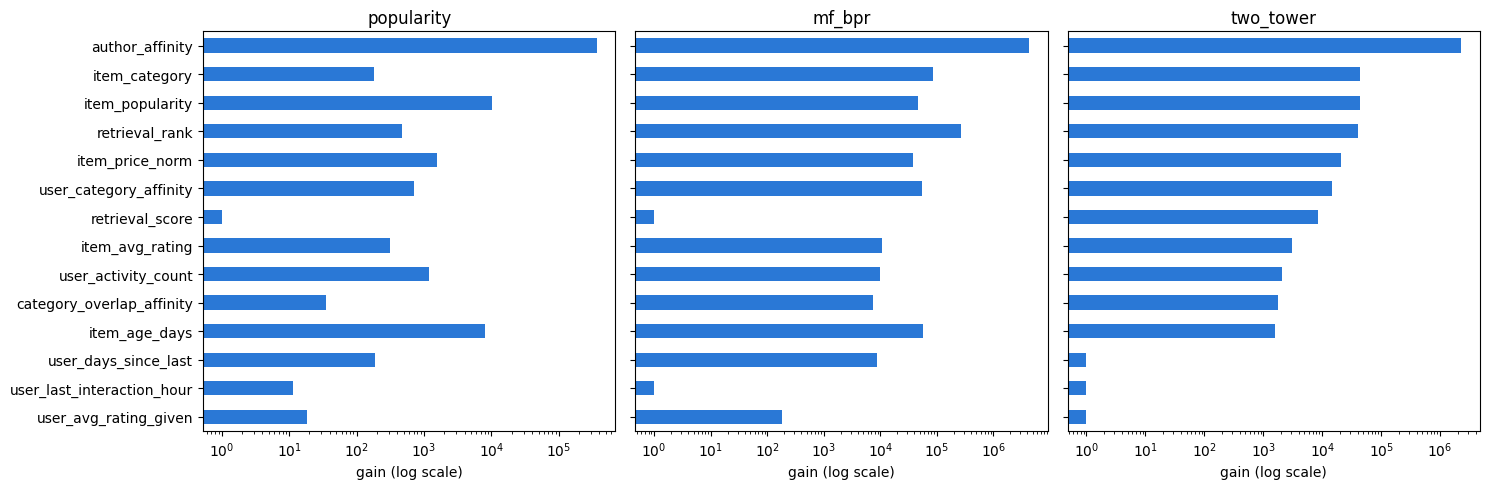


popularity:
author_affinity               364286.677979
item_popularity                10283.875853
item_age_days                   8040.859814
item_price_norm                 1542.936157
user_activity_count             1173.543099
user_category_affinity           713.960126
retrieval_rank                   466.788365
item_avg_rating                  309.828896
user_days_since_last             187.169336
item_category                    182.501007
category_overlap_affinity         35.345890
user_avg_rating_given             18.244570
user_last_interaction_hour        11.474300
retrieval_score                    0.000000
dtype: float64

mf_bpr:
author_affinity               4.259850e+06
retrieval_rank                2.723384e+05
item_category                 8.686653e+04
item_age_days                 5.743887e+04
user_category_affinity        5.431449e+04
item_popularity               4.737804e+04
item_price_norm               3.750371e+04
item_avg_rating               1.063477e+04
use

In [100]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
feature_order = all_importance["two_tower"].sort_values(ascending=True).index

for ax, name in zip(axes, RETRIEVERS.keys()):
    all_importance[name].reindex(feature_order).clip(lower=1).plot(kind="barh", ax=ax, color="#2a78d6")
    ax.set_title(name)
    ax.set_xlabel("gain (log scale)")
    ax.set_xscale("log")

plt.tight_layout()
plt.show()

for name, imp in all_importance.items():
    print(f"\n{name}:")
    print(imp)

## 14. Summary / notes for `ANALYSIS.md`

**What this notebook delivers.** 14 features across all 4 required groups, and three full retrieval → ranking pipelines (Popularity, MF-BPR, Two-tower), each with its own LightGBM `lambdarank` ranker and its own retrieval-only vs. +LightGBM comparison — a direct, complete answer to project.md's "compare Popularity vs MF-BPR vs Two-tower" requirement.

**Caveats to carry into `ANALYSIS.md`:**

1. **Two-tower is the strongest retriever across every metric** — NDCG@10, Recall@20/50, and catalog coverage, both before and after ranking. Popularity is weakest across the board, including catalog coverage, since it recommends the same items to everyone. If the team needs to pick a single retriever for production, this run is the evidence.
2. **No impression logs → graded proxy labels.** Amazon Reviews has no "shown but not acted on" signal, so `label∈{0,1,2}` is the closest available proxy — a dataset limitation, not a shortcut we chose.
3. **`author_affinity` dominates feature importance in all three rankers** — the one feature this session added that no other notebook uses. That it holds up regardless of which retriever supplied the candidates is a stronger result than any single run could show on its own.
4. **Early stopping is aggressive for Popularity and MF-BPR** (`best_iteration` in the low single digits) but not for Two-tower — label=2 is under 1% of train rows overall, but Two-tower's more relevant candidate pool gives the model more to learn from before converging.
5. **Columns still dropped** from the raw JSONL: `store`, `rating_number`, `details`, review `text`/`images`/`helpful_vote`/`asin`, product `videos`, `bought_together`, `subtitle`. Only `author` and the full `categories` path were added — the two flagged as highest-value.

## 15. Multi-source retrieval: blending candidates

A fourth pipeline: instead of one retriever, blend all three into a single ~100-candidate pool per user — **60 from Two-tower + 30 from MF-BPR + 10 from Popularity**, weighted toward the two stronger retrievers from the comparison above.

Each source's `retrieval_score` lives on a different scale (FAISS inner product for Two-tower/MF-BPR vs. a normalized interaction ratio for Popularity), so a `retrieval_source` categorical feature is added — it lets the ranker learn to interpret the score correctly per source, something the three independent pipelines above didn't need.

If the same item is retrieved by more than one source for a user, it's kept once (priority Two-tower > MF-BPR > Popularity, matching the quota order) and not backfilled — so per-user candidate counts can run slightly under 100. `retrieval_only` here is a weaker baseline than in the single-retriever pipelines, since ranking blended, differently-scaled scores directly doesn't have a natural meaning — it's included mainly as a sanity floor.

In [101]:
MULTI_SOURCE_QUOTA = [
    ("two_tower", two_tower_candidates, 60),
    ("mf_bpr", mf_bpr_candidates, 30),
    ("popularity", popularity_candidates, 10),
]


def multi_source_candidates(users, seen_sets=None):
    parts = []
    for source_name, candidate_fn, quota in MULTI_SOURCE_QUOTA:
        cand = candidate_fn(users, seen_sets=seen_sets)
        cand = cand.sort_values(["user_id", "retrieval_rank"]).groupby("user_id", group_keys=False).head(quota)
        cand["retrieval_source"] = source_name
        parts.append(cand)
    combined = pd.concat(parts, ignore_index=True)
    # dedup: keep first occurrence per (user, item) -> priority two_tower > mf_bpr > popularity
    return combined.drop_duplicates(subset=["user_id", "parent_asin"], keep="first")


print(f"Multi-source retriever ready: quota = {dict((n, q) for n, _, q in MULTI_SOURCE_QUOTA)}   ({time.time()-t0:.1f}s)")

Multi-source retriever ready: quota = {'two_tower': 60, 'mf_bpr': 30, 'popularity': 10}   (273.3s)


`multi_source_candidates` above can undershoot 100/user when sources overlap (see previous discussion). `multi_source_candidates_100` fixes that with a waterfall: take 10 from Popularity, then 30 from MF-BPR excluding those 10, then 60 from Two-tower excluding all 40 already picked. Since each retriever already returns up to 100 ranked candidates/user, there's always enough left after exclusion to fill each quota — so this reaches exactly 100/user (barring a user missing from MF-BPR/Two-tower's vocab entirely, same edge case as the rest of the notebook).

In [102]:
def _exclude_and_take(cand, exclude, n):
    if exclude is not None and len(exclude) > 0:
        cand = cand.merge(exclude, on=["user_id", "parent_asin"], how="left", indicator=True)
        cand = cand[cand["_merge"] == "left_only"].drop(columns="_merge")
    return cand.sort_values(["user_id", "retrieval_rank"]).groupby("user_id", group_keys=False).head(n)


def multi_source_candidates_100(users, seen_sets=None):
    """Waterfall so per-user count hits exactly 100: 10 popularity -> 30 mf_bpr (excl. those 10) -> 60 two_tower (excl. those 40)."""
    pop = _exclude_and_take(popularity_candidates(users, seen_sets=seen_sets), None, 10)
    pop["retrieval_source"] = "popularity"

    mf = _exclude_and_take(mf_bpr_candidates(users, seen_sets=seen_sets), pop[["user_id", "parent_asin"]], 30)
    mf["retrieval_source"] = "mf_bpr"

    picked_so_far = pd.concat([pop[["user_id", "parent_asin"]], mf[["user_id", "parent_asin"]]], ignore_index=True)
    tt = _exclude_and_take(two_tower_candidates(users, seen_sets=seen_sets), picked_so_far, 60)
    tt["retrieval_source"] = "two_tower"

    return pd.concat([pop, mf, tt], ignore_index=True)


print(f"multi_source_candidates_100 ready: quota = popularity(10) -> mf_bpr(30) -> two_tower(60)   ({time.time()-t0:.1f}s)")

multi_source_candidates_100 ready: quota = popularity(10) -> mf_bpr(30) -> two_tower(60)   (273.3s)


## 16. Train LightGBM on the blended candidates

Same labels/features/metrics as the three pipelines above, plus `retrieval_source` as an extra categorical feature. Results are added into the same `all_results`/`all_importance`/`boosters` dicts (so section 12's pattern still works if re-run) and saved to `checkpoints/lightgbm_ranker/multi_source/`.

In [103]:
MULTI_SOURCE_FEATURE_COLUMNS = FEATURE_COLUMNS + ["retrieval_source"]

print(f"\n=== multi_source ===  ({time.time()-t0:.1f}s)")
tr_cand = build_labels(multi_source_candidates(train_users, seen_sets=None), train)
va_cand = build_labels(multi_source_candidates(val_users, seen_sets=train_seen), val)
te_cand = build_labels(multi_source_candidates(test_users, seen_sets=train_seen), test)
print(f"  candidates: train={tr_cand.shape} val={va_cand.shape} test={te_cand.shape}   ({time.time()-t0:.1f}s)")

tr_feat = build_feature_table(tr_cand)
va_feat = build_feature_table(va_cand)
te_feat = build_feature_table(te_cand)

all_genres = pd.concat([tr_feat["item_category"], va_feat["item_category"], te_feat["item_category"]]).unique()
genre_dtype = pd.CategoricalDtype(categories=sorted([g for g in all_genres if pd.notna(g)]))
source_dtype = pd.CategoricalDtype(categories=[name for name, _, _ in MULTI_SOURCE_QUOTA])
for d in (tr_feat, va_feat, te_feat):
    d["item_category"] = d["item_category"].astype(genre_dtype)
    d["retrieval_source"] = d["retrieval_source"].astype(source_dtype)

tr_feat, tr_group = to_group(tr_feat)
va_feat, va_group = to_group(va_feat)
te_feat, te_group = to_group(te_feat)

train_set = lgb.Dataset(tr_feat[MULTI_SOURCE_FEATURE_COLUMNS], label=tr_feat["label"], group=tr_group, categorical_feature=["item_category", "retrieval_source"])
val_set = lgb.Dataset(va_feat[MULTI_SOURCE_FEATURE_COLUMNS], label=va_feat["label"], group=va_group, categorical_feature=["item_category", "retrieval_source"], reference=train_set)

val_feval = make_honest_ndcg_feval(va_feat["user_id"].values, k=10)
lgb_params = {
    "objective": "lambdarank", "metric": "None", "learning_rate": 0.05,
    "num_leaves": 31, "min_data_in_leaf": 50, "verbose": -1, "seed": SEED,
}
booster = lgb.train(
    lgb_params, train_set, num_boost_round=300, valid_sets=[val_set], valid_names=["val"],
    feval=val_feval, callbacks=[lgb.early_stopping(30), lgb.log_evaluation(0)],
)
print(f"  best_iteration={booster.best_iteration}   ({time.time()-t0:.1f}s)")

va_feat["lgb_score"] = booster.predict(va_feat[MULTI_SOURCE_FEATURE_COLUMNS])
te_feat["lgb_score"] = booster.predict(te_feat[MULTI_SOURCE_FEATURE_COLUMNS])

res = {}
for split_name, df in [("val", va_feat), ("test", te_feat)]:
    res[(split_name, "retrieval_only")] = evaluate(df, "retrieval_score")
    res[(split_name, "lightgbm")] = evaluate(df, "lgb_score")
all_results["multi_source"] = res
all_importance["multi_source"] = pd.Series(booster.feature_importance(importance_type="gain"), index=MULTI_SOURCE_FEATURE_COLUMNS).sort_values(ascending=False)
boosters["multi_source"] = booster

out_dir = CKPT_DIR / "multi_source"
out_dir.mkdir(parents=True, exist_ok=True)
booster.save_model(str(out_dir / "lightgbm_ranker.txt"))
with open(out_dir / "metadata.json", "w") as f:
    json.dump({"retriever": "multi_source", "feature_columns": MULTI_SOURCE_FEATURE_COLUMNS, "best_iteration": booster.best_iteration}, f, indent=2)
print(f"  saved -> {out_dir}")


=== multi_source ===  (273.3s)
  candidates: train=(4559142, 6) val=(974987, 6) test=(584590, 6)   (303.3s)
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[40]	val's ndcg@10_honest: 0.190268
  best_iteration=40   (366.7s)
  saved -> E:\EPITA\Recommended System\recsys_amazon_book\checkpoints\lightgbm_ranker\multi_source


## 16b. Train LightGBM on the exactly-100 blend

Same pipeline as section 16, swapped to `multi_source_candidates_100`. Results go into the same `all_results`/`all_importance`/`boosters` dicts under the key `"multi_source_100"`, saved to `checkpoints/lightgbm_ranker/multi_source_100/` — directly comparable to `multi_source` in the section 17 table.

In [104]:
print(f"\n=== multi_source_100 ===  ({time.time()-t0:.1f}s)")
tr_cand = build_labels(multi_source_candidates_100(train_users, seen_sets=None), train)
va_cand = build_labels(multi_source_candidates_100(val_users, seen_sets=train_seen), val)
te_cand = build_labels(multi_source_candidates_100(test_users, seen_sets=train_seen), test)
print(f"  candidates: train={tr_cand.shape} val={va_cand.shape} test={te_cand.shape}   ({time.time()-t0:.1f}s)")

tr_feat = build_feature_table(tr_cand)
va_feat = build_feature_table(va_cand)
te_feat = build_feature_table(te_cand)

all_genres = pd.concat([tr_feat["item_category"], va_feat["item_category"], te_feat["item_category"]]).unique()
genre_dtype = pd.CategoricalDtype(categories=sorted([g for g in all_genres if pd.notna(g)]))
source_dtype = pd.CategoricalDtype(categories=["popularity", "mf_bpr", "two_tower"])
for d in (tr_feat, va_feat, te_feat):
    d["item_category"] = d["item_category"].astype(genre_dtype)
    d["retrieval_source"] = d["retrieval_source"].astype(source_dtype)

tr_feat, tr_group = to_group(tr_feat)
va_feat, va_group = to_group(va_feat)
te_feat, te_group = to_group(te_feat)

train_set = lgb.Dataset(tr_feat[MULTI_SOURCE_FEATURE_COLUMNS], label=tr_feat["label"], group=tr_group, categorical_feature=["item_category", "retrieval_source"])
val_set = lgb.Dataset(va_feat[MULTI_SOURCE_FEATURE_COLUMNS], label=va_feat["label"], group=va_group, categorical_feature=["item_category", "retrieval_source"], reference=train_set)

val_feval = make_honest_ndcg_feval(va_feat["user_id"].values, k=10)
lgb_params = {
    "objective": "lambdarank", "metric": "None", "learning_rate": 0.05,
    "num_leaves": 31, "min_data_in_leaf": 50, "verbose": -1, "seed": SEED,
}
booster = lgb.train(
    lgb_params, train_set, num_boost_round=300, valid_sets=[val_set], valid_names=["val"],
    feval=val_feval, callbacks=[lgb.early_stopping(30), lgb.log_evaluation(0)],
)
print(f"  best_iteration={booster.best_iteration}   ({time.time()-t0:.1f}s)")

va_feat["lgb_score"] = booster.predict(va_feat[MULTI_SOURCE_FEATURE_COLUMNS])
te_feat["lgb_score"] = booster.predict(te_feat[MULTI_SOURCE_FEATURE_COLUMNS])

res = {}
for split_name, df in [("val", va_feat), ("test", te_feat)]:
    res[(split_name, "retrieval_only")] = evaluate(df, "retrieval_score")
    res[(split_name, "lightgbm")] = evaluate(df, "lgb_score")
all_results["multi_source_100"] = res
all_importance["multi_source_100"] = pd.Series(booster.feature_importance(importance_type="gain"), index=MULTI_SOURCE_FEATURE_COLUMNS).sort_values(ascending=False)
boosters["multi_source_100"] = booster

out_dir = CKPT_DIR / "multi_source_100"
out_dir.mkdir(parents=True, exist_ok=True)
booster.save_model(str(out_dir / "lightgbm_ranker.txt"))
with open(out_dir / "metadata.json", "w") as f:
    json.dump({"retriever": "multi_source_100", "feature_columns": MULTI_SOURCE_FEATURE_COLUMNS, "best_iteration": booster.best_iteration}, f, indent=2)
print(f"  saved -> {out_dir}")


=== multi_source_100 ===  (380.8s)
  candidates: train=(4819900, 6) val=(1017900, 6) test=(609600, 6)   (417.7s)
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[2]	val's ndcg@10_honest: 0.177084
  best_iteration=2   (474.3s)
  saved -> E:\EPITA\Recommended System\recsys_amazon_book\checkpoints\lightgbm_ranker\multi_source_100


## 17. Compare all 5 pipelines

Reuses `all_results`, now holding all 5 (Popularity, MF-BPR, Two-tower, Multi-source, Multi-source-100). Logging is scoped by retriever name (not by dropping the whole `stage=="ranking"` block) so it only replaces these 5 pipelines' own rows in `reports/ranking_metrics.csv`, leaving any other retriever's rows untouched even if this cell is re-run on its own.

In [105]:
rows = []
for retriever_name, res in all_results.items():
    for (split_name, model_name), metrics in res.items():
        row = {"stage": "ranking", "retriever": retriever_name, "model": model_name, "split": split_name}
        row.update(metrics)
        rows.append(row)
final_df = pd.DataFrame(rows)

RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)
if RESULTS_PATH.exists():
    existing = pd.read_csv(RESULTS_PATH)
    existing = existing[~((existing["stage"] == "ranking") & (existing["retriever"].isin(final_df["retriever"].unique())))]
    combined = pd.concat([existing, final_df], ignore_index=True)
else:
    combined = final_df
combined.to_csv(RESULTS_PATH, index=False)
print(f"Saved -> {RESULTS_PATH}")

final_df.set_index(["retriever", "split", "model"]).sort_index()

Saved -> E:\EPITA\Recommended System\recsys_amazon_book\reports\ranking_metrics.csv


stage   ndcg@10  recall@20  \
retriever        split model                                          
mf_bpr           test  lightgbm        ranking  0.136052   0.382707   
                       retrieval_only  ranking  0.095768   0.327690   
                 val   lightgbm        ranking  0.170543   0.454090   
                       retrieval_only  ranking  0.094546   0.308208   
multi_source     test  lightgbm        ranking  0.152345   0.423154   
                       retrieval_only  ranking  0.088617   0.301765   
                 val   lightgbm        ranking  0.190268   0.508924   
                       retrieval_only  ranking  0.069533   0.231412   
multi_source_100 test  lightgbm        ranking  0.153301   0.433405   
                       retrieval_only  ranking  0.100498   0.344669   
                 val   lightgbm        ranking  0.177084   0.476507   
                       retrieval_only  ranking  0.085736   0.284362   
popularity       test  lightgbm        ranking  0.123751   0.274045   
                       retrieval_only  ranking  0.050469   0.210474   
                 val   lightgbm        ranking  0.132527   0.350368   
                       retrieval_only  ranking  0.066205   0.222529   
two_tower        test  lightgbm        ranking  0.163908   0.441609   
                       retrieval_only  ranking  0.087430   0.310722   
                 val   lightgbm        ranking  0.202215   0.519039   
                       retrieval_only  ranking  0.102918   0.349833   

                                       recall@50  catalog_coverage  
retriever        split model                                        
mf_bpr           test  lightgbm         0.667700          0.286814  
                       retrieval_only   0.619575          0.211420  
                 val   lightgbm         0.673213          0.329451  
                       retrieval_only   0.627970          0.241503  
multi_source     test  lightgbm         0.714458          0.473660  
                       retrieval_only   0.618376          0.227438  
                 val   lightgbm         0.761400          0.553657  
                       retrieval_only   0.619624          0.258753  
multi_source_100 test  lightgbm         0.712504          0.409634  
                       retrieval_only   0.639625          0.229414  
                 val   lightgbm         0.718684          0.483656  
                       retrieval_only   0.621387          0.260008  
popularity       test  lightgbm         0.567852          0.002581  
                       retrieval_only   0.500988          0.000744  
                 val   lightgbm         0.616943          0.002697  
                       retrieval_only   0.465316          0.000744  
two_tower        test  lightgbm         0.691116          0.503673  
                       retrieval_only   0.627963          0.512205  
                 val   lightgbm         0.735210          0.583275  
                       retrieval_only   0.647015          0.589343

## 18. Feature importance: multi-source vs. multi-source-100

Both include `retrieval_source`, which the three single-retriever pipelines didn't have.

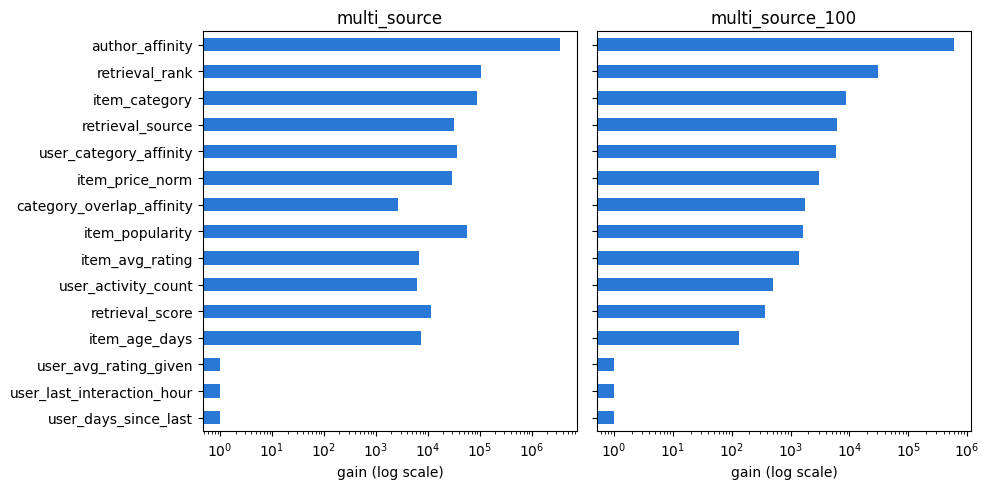


multi_source:
author_affinity               3.537362e+06
retrieval_rank                1.061594e+05
item_category                 8.738189e+04
item_popularity               5.624444e+04
user_category_affinity        3.636861e+04
retrieval_source              3.253653e+04
item_price_norm               2.889004e+04
retrieval_score               1.172568e+04
item_age_days                 7.551463e+03
item_avg_rating               6.789288e+03
user_activity_count           6.099062e+03
category_overlap_affinity     2.690787e+03
user_last_interaction_hour    0.000000e+00
user_avg_rating_given         0.000000e+00
user_days_since_last          0.000000e+00
dtype: float64

multi_source_100:
author_affinity               599114.000000
retrieval_rank                 30892.176376
item_category                   8858.830788
retrieval_source                6136.801086
user_category_affinity          6036.144981
item_price_norm                 3042.850967
category_overlap_affinity       1743.65402

In [106]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
feature_order = all_importance["multi_source_100"].sort_values(ascending=True).index

for ax, name in zip(axes, ["multi_source", "multi_source_100"]):
    all_importance[name].reindex(feature_order).clip(lower=1).plot(kind="barh", ax=ax, color="#2a78d6")
    ax.set_title(name)
    ax.set_xlabel("gain (log scale)")
    ax.set_xscale("log")

plt.tight_layout()
plt.show()

for name in ["multi_source", "multi_source_100"]:
    print(f"\n{name}:")
    print(all_importance[name])